In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit 
%matplotlib inline
import matplotlib as mlt

In [2]:
# Formating options for the plot
import pylab
params = {'backend': 'ps',
          'axes.labelsize': 20,
          'legend.fontsize': 20,
          'legend.handlelength': 2.0,
          'legend.borderaxespad': 0,
          'xtick.labelsize': 20,
          'ytick.labelsize': 20,
          'font.family': 'serif',
          'font.size': 20,
          'font.weight': 'normal',
          'font.serif': ['Times New Roman'],
          'ps.usedistiller': 'xpdf',
          'text.usetex': False}
pylab.rcParams.update(params)

In [3]:
# Plot size setup
fw = 15
fh = 10
fsl = 20
fsl2 = 24

In [4]:
df1 = pd.read_csv("AF_TI_Higher.csv")

df2 = df1.loc[1400:1600]
df2 = df2.reset_index()
df2

,index,Years,A,B,DOC,Fa,Fal,Fbm,Fi,Fl,...,Fpl,L,M,P,decomp,ksstr,lk,npp_,phi,s
0,1400,1401,636.683466,167.608047,262.281691,0.089763,0.002939,0.829694,0.166976,0.000946,...,0.432133,59.212249,1765.475786,358.243523,0.208721,0.511213,2.301006e-07,1.330137,0.556801,0.348414
1,1401,1402,542.957633,149.997468,272.625653,0.064502,0.002074,0.742540,0.142498,0.000569,...,0.377444,67.970808,1744.732072,454.697853,0.178123,0.377422,1.365019e-07,1.330137,0.541936,0.291518
2,1402,1403,551.077550,136.203249,297.865596,0.053750,0.001706,0.674253,0.138825,0.000066,...,0.355316,67.987150,1747.603720,445.185778,0.173532,0.401396,1.152048e-08,1.330137,0.544600,0.269430
3,1403,1404,584.186809,135.194403,305.501358,0.067337,0.002140,0.669239,0.156723,0.000065,...,0.397681,65.406088,1758.439853,416.743973,0.195904,0.450396,9.907235e-09,1.330137,0.550044,0.297615
4,1404,1405,571.294509,140.236587,302.376032,0.066353,0.002120,0.694203,0.150901,0.000381,...,0.389930,66.312390,1757.539785,431.154705,0.188627,0.430181,7.187537e-08,1.330137,0.547798,0.298273
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,1596,1597,1791.515762,127.854262,240.845680,0.195917,0.006131,0.632916,0.350659,0.000072,...,0.216819,162.889769,1731.500829,120.973365,0.438324,0.898965,1.405756e-08,1.330137,0.599885,0.284058
197,1597,1598,1791.763789,125.469461,245.258942,0.200934,0.006270,0.621107,0.376564,0.000017,...,0.227130,164.955475,1732.968629,126.021730,0.470705,0.898966,3.166496e-09,1.330137,0.599885,0.285919
198,1598,1599,1792.615392,125.587635,246.454731,0.203651,0.006354,0.621691,0.383580,0.002028,...,0.234927,166.164644,1737.109945,129.711202,0.479475,0.898969,6.325917e-07,1.330137,0.599885,0.298009
199,1599,1600,1793.654584,134.302468,232.773405,0.242111,0.007632,0.664822,0.420573,0.001279,...,0.282927,154.421396,1744.808431,130.599857,0.525717,0.898972,3.585581e-07,1.330137,0.599886,0.334531


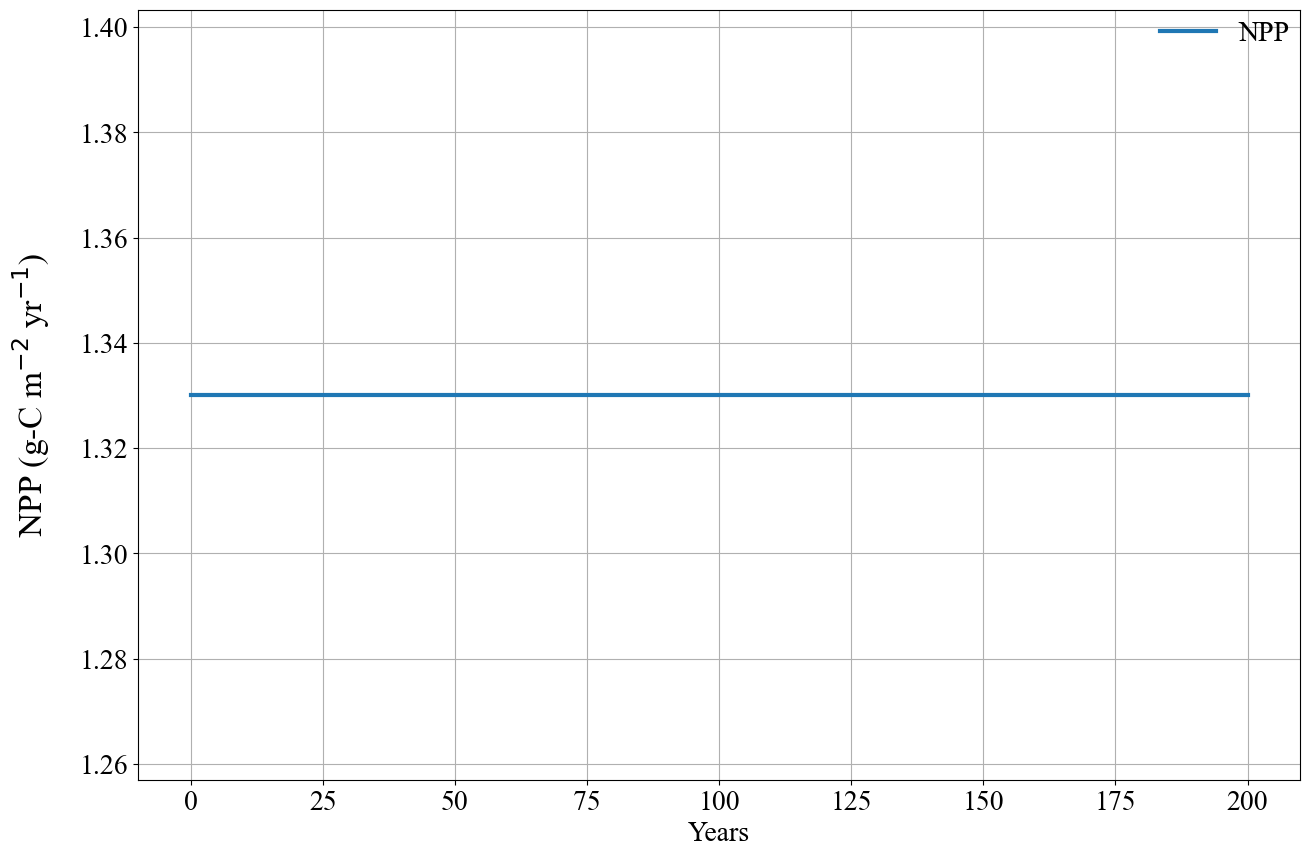

In [9]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["npp_"], lw=3, label="NPP")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'NPP (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

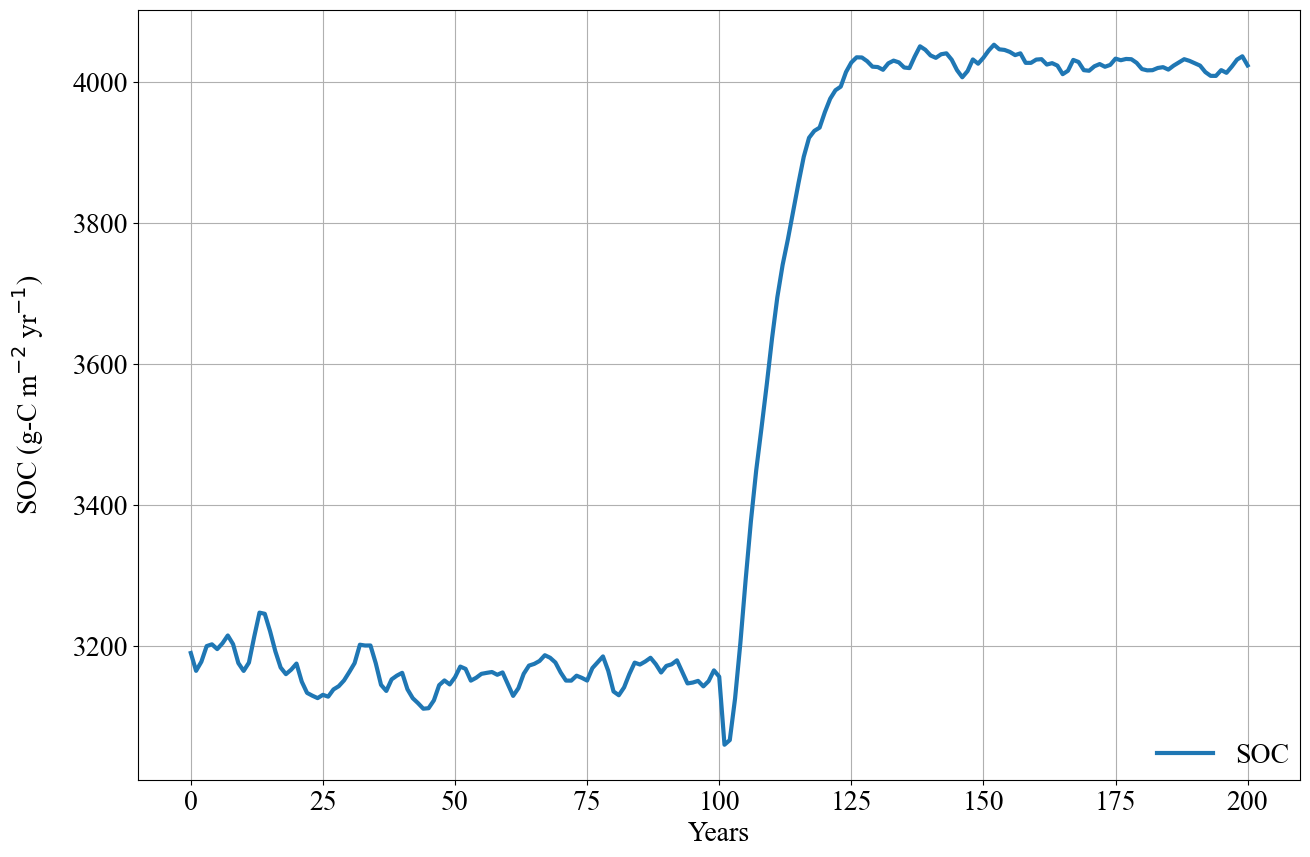

In [11]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["P"] + df2['A'] + df2['M'] + df2['B'] + df2['DOC'], lw=3, label="SOC")

ax1.grid(True)
ax1.legend(frameon=False, loc="lower right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'SOC (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

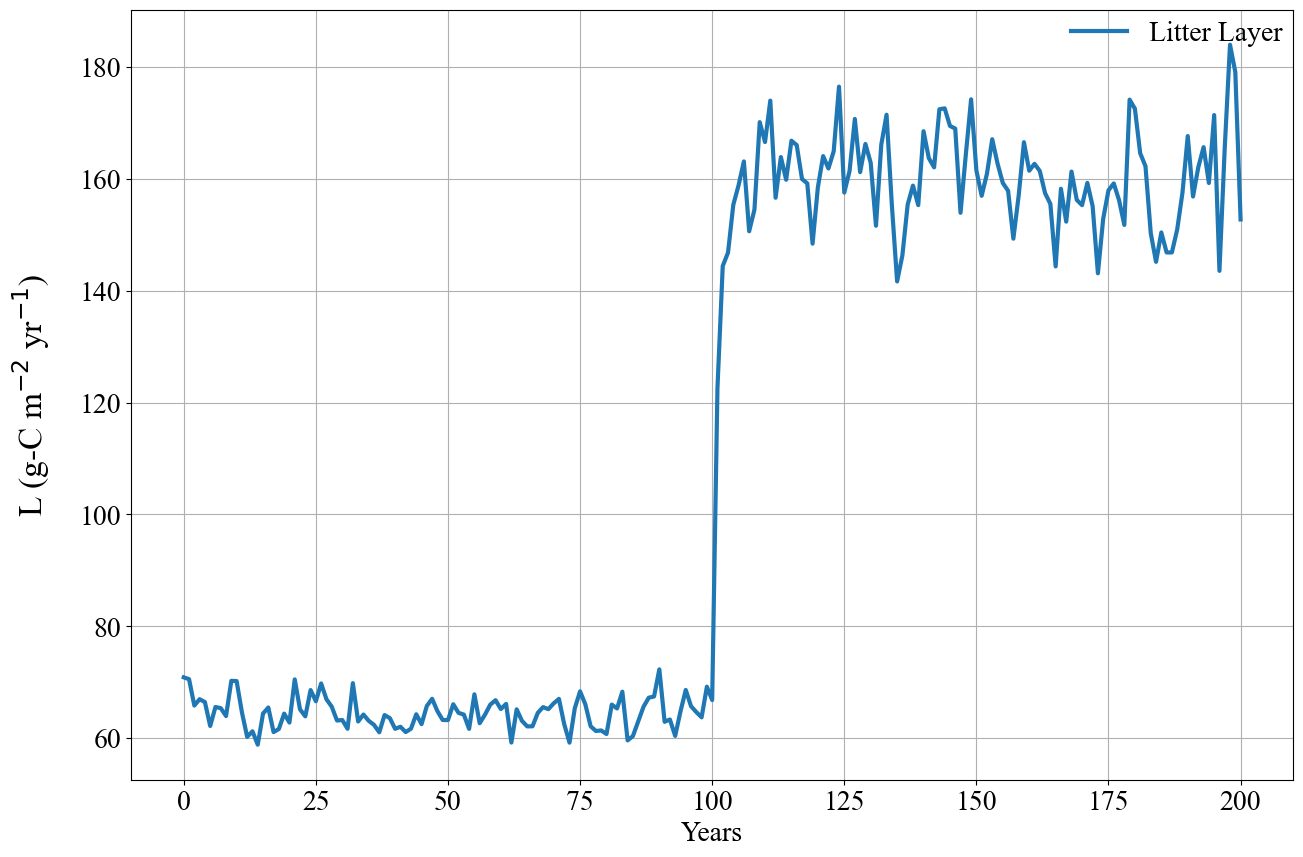

In [13]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["L"], lw=3, label="Litter Layer")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'L (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

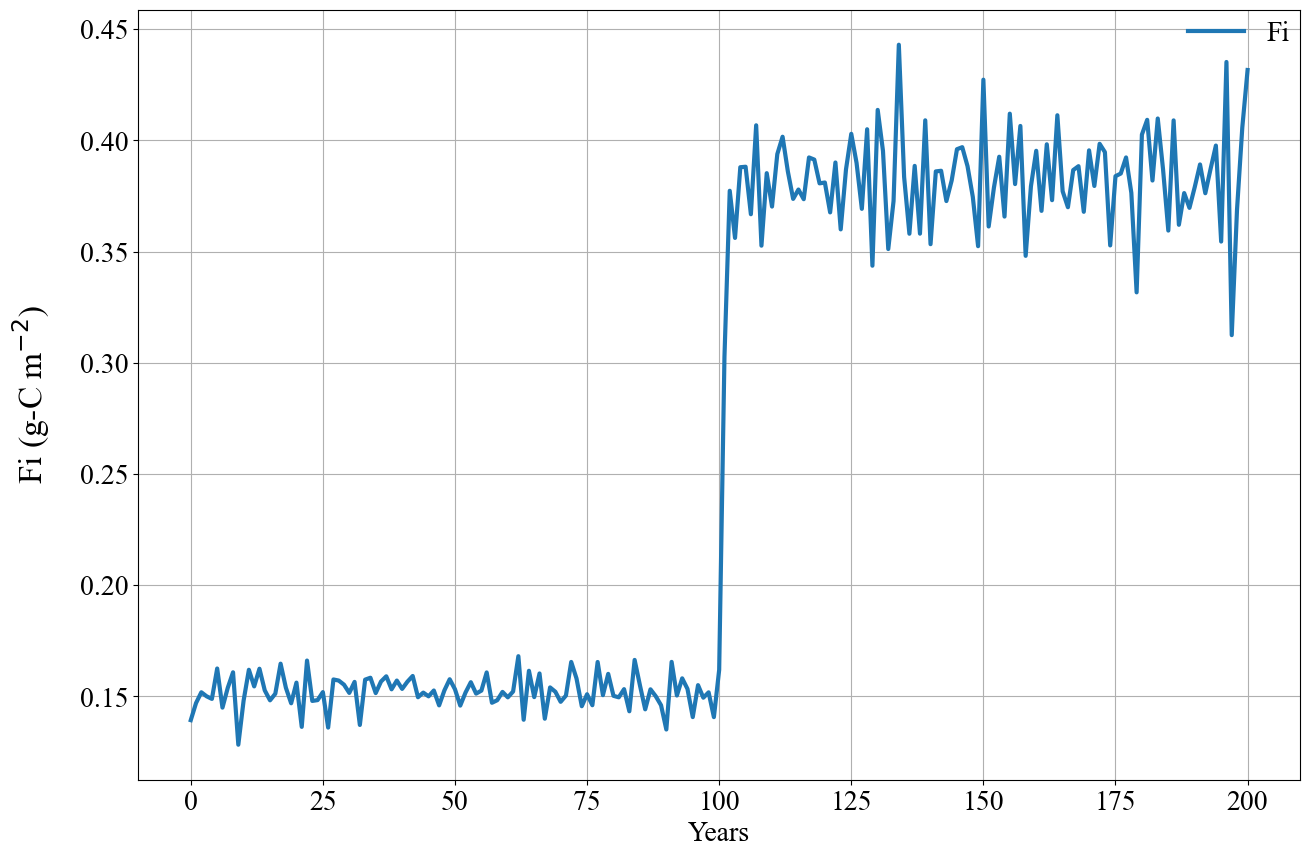

In [14]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fi"], lw=3, label="Fi")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fi (g-C m$^{-2}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

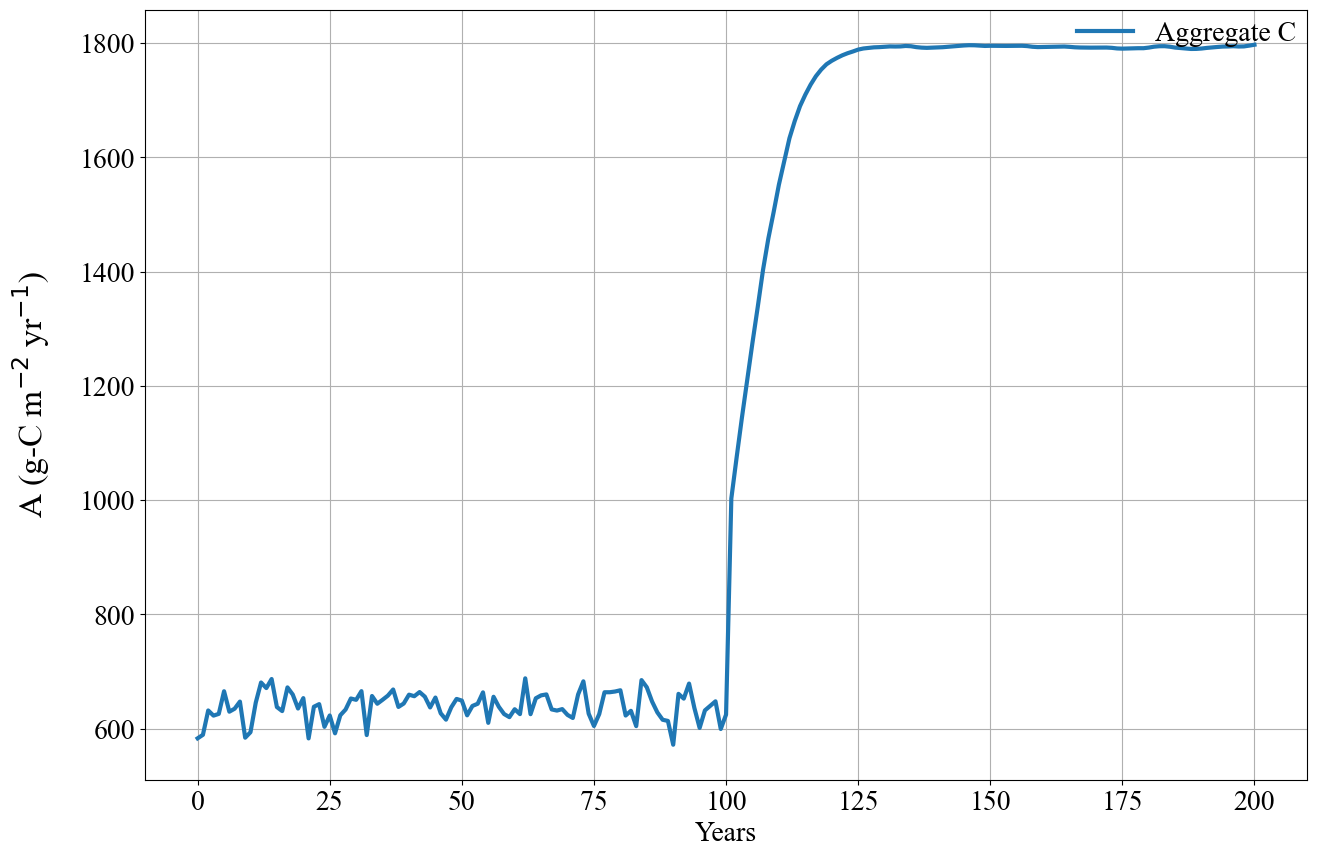

In [16]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["A"], lw=3, label="Aggregate C")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'A (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

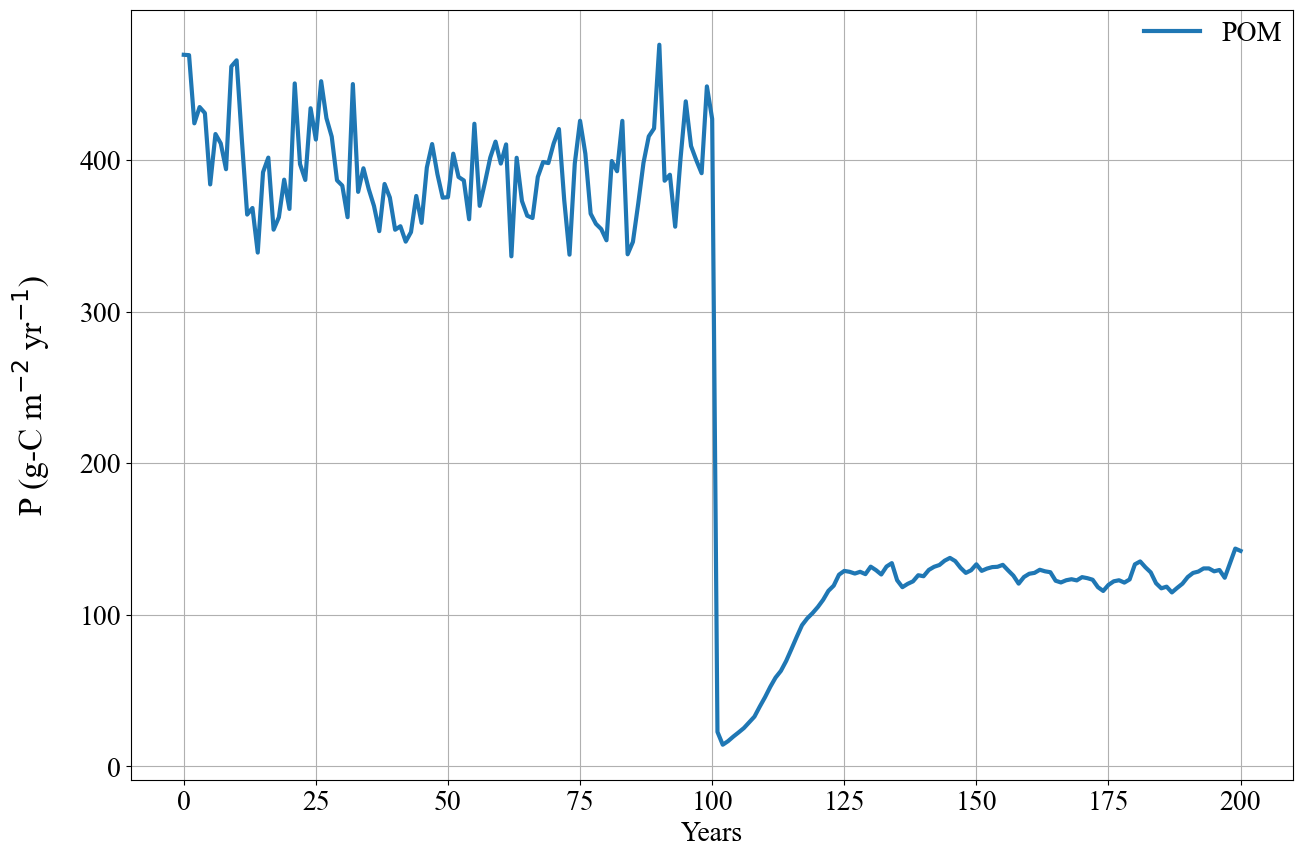

In [17]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["P"], lw=3, label="POM")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'P (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

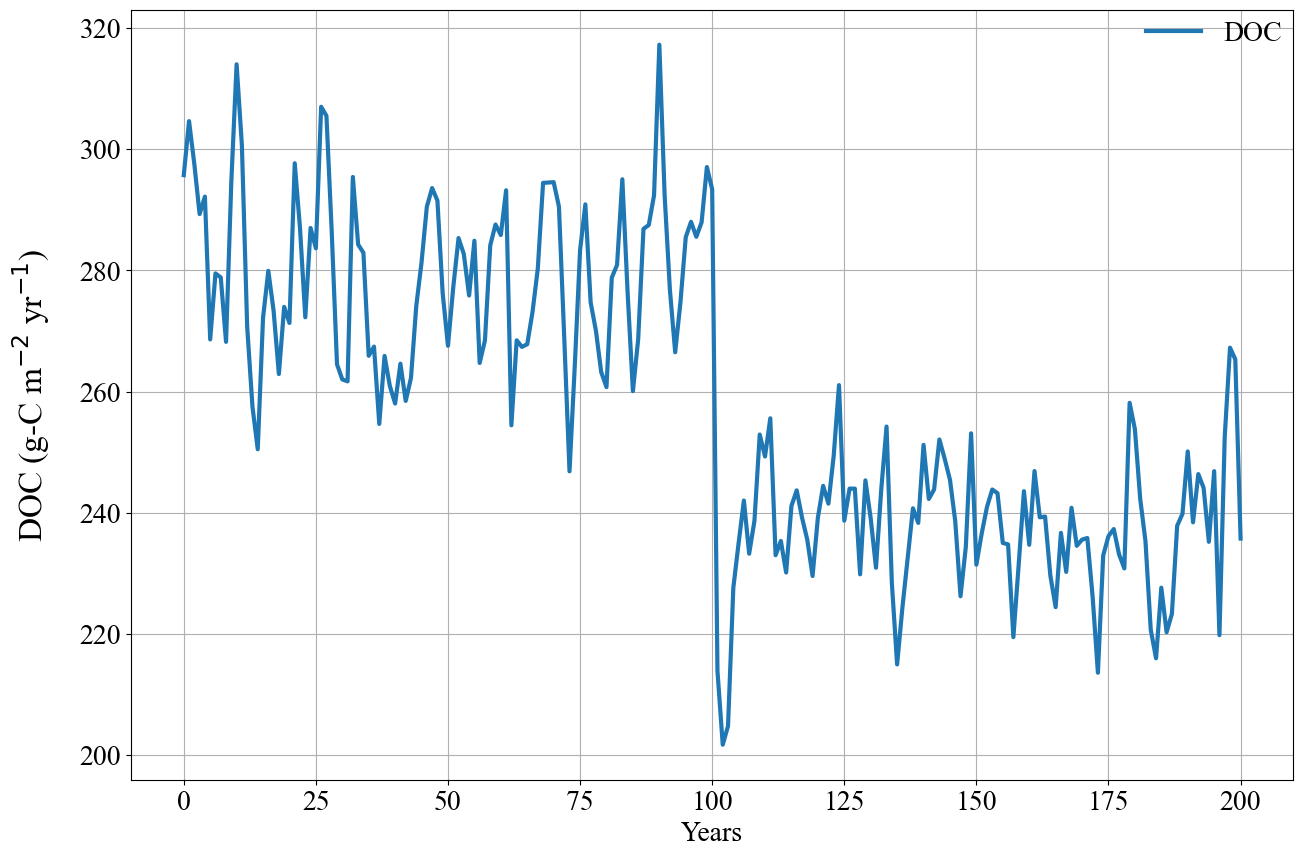

In [18]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["DOC"], lw=3, label="DOC")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'DOC (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

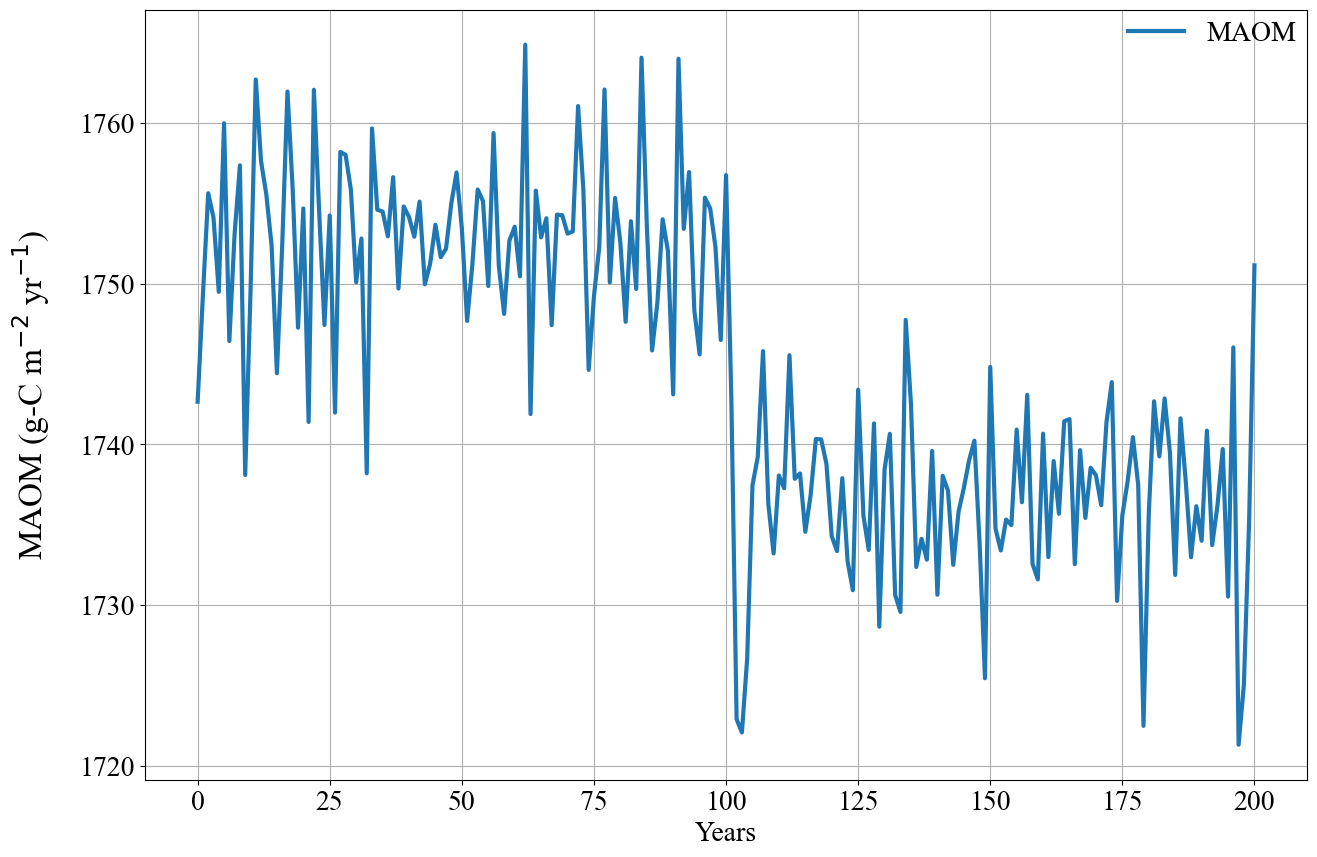

In [20]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["M"], lw=3, label="MAOM")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'MAOM (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

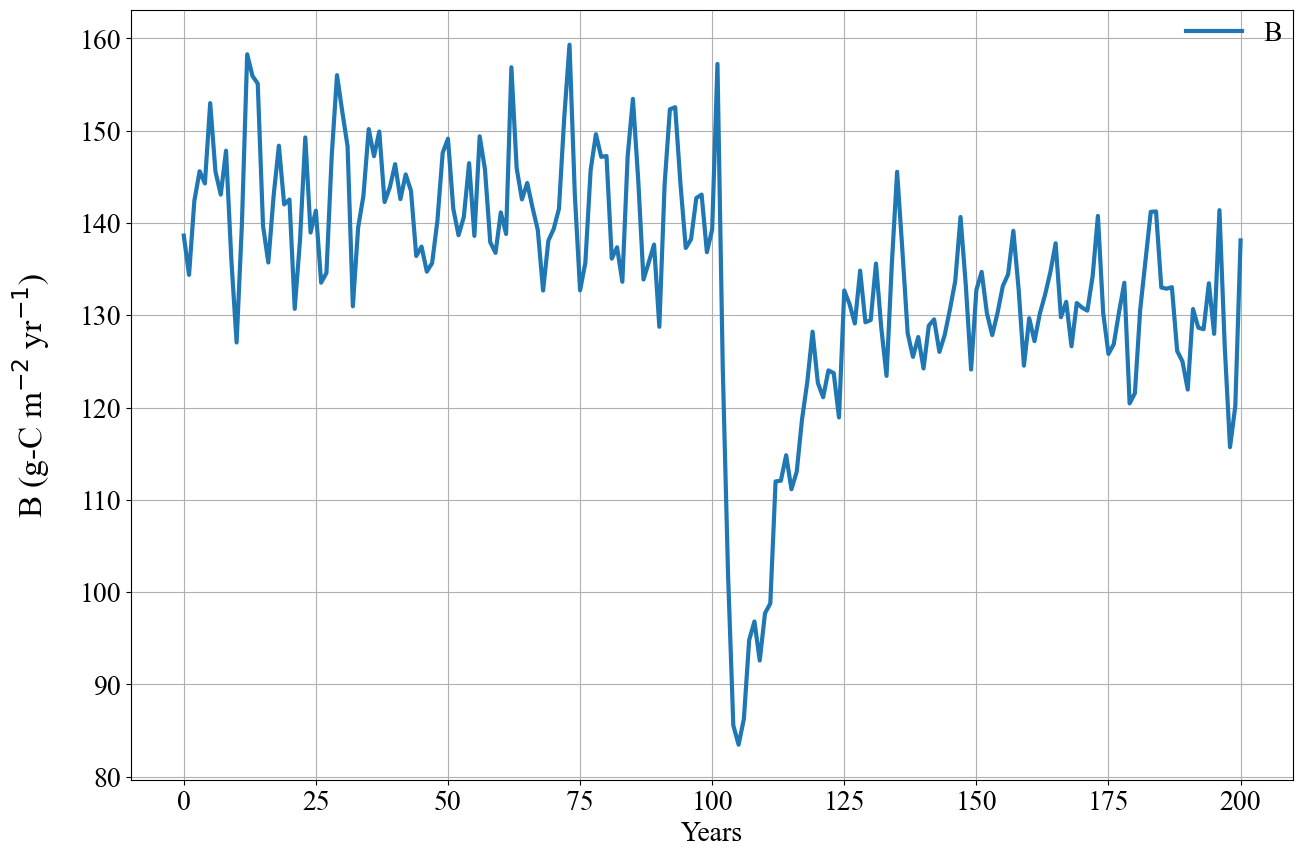

In [21]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["B"], lw=3, label="B")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'B (g-C m$^{-2}$ yr$^{-1}$)', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

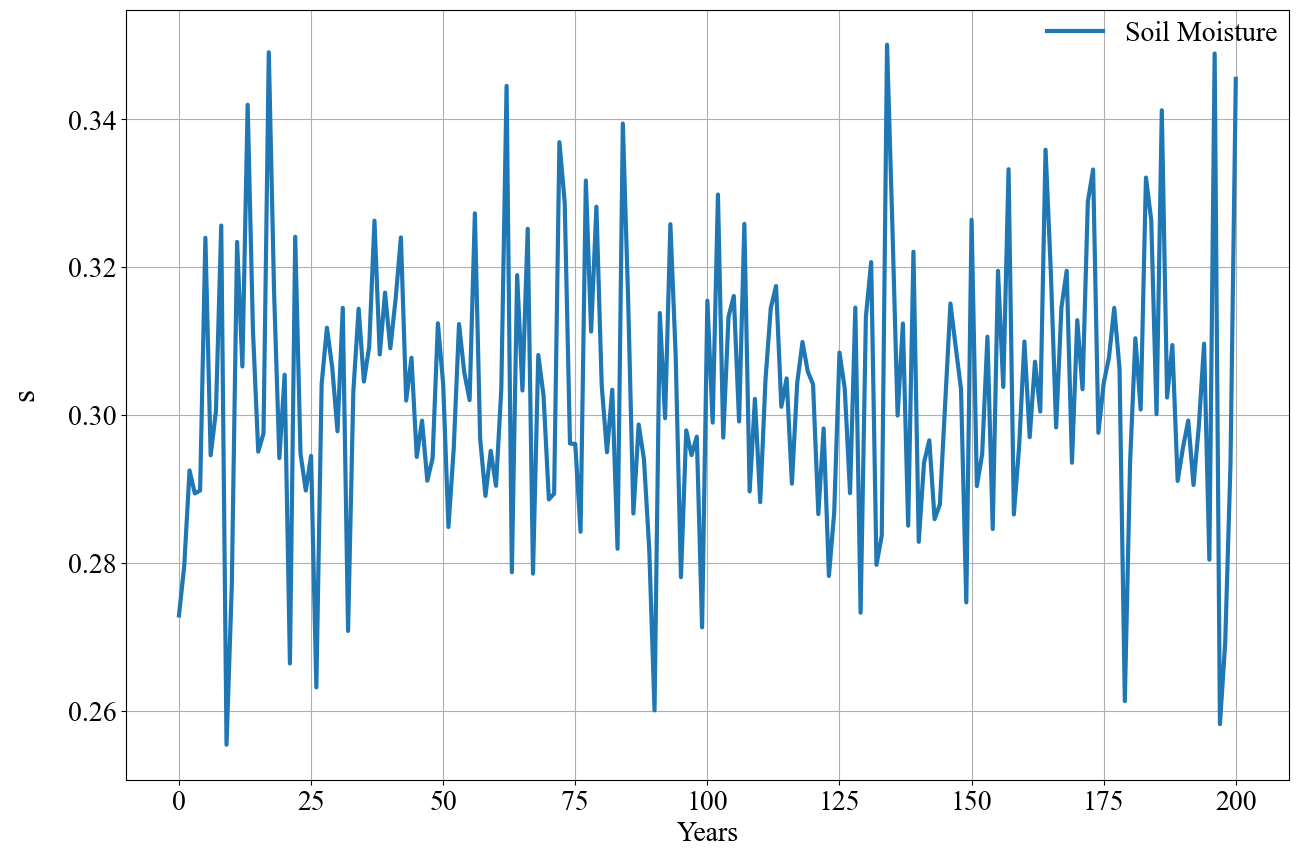

In [22]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["s"], lw=3, label="Soil Moisture")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r's', rotation=90, fontsize=fsl2, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

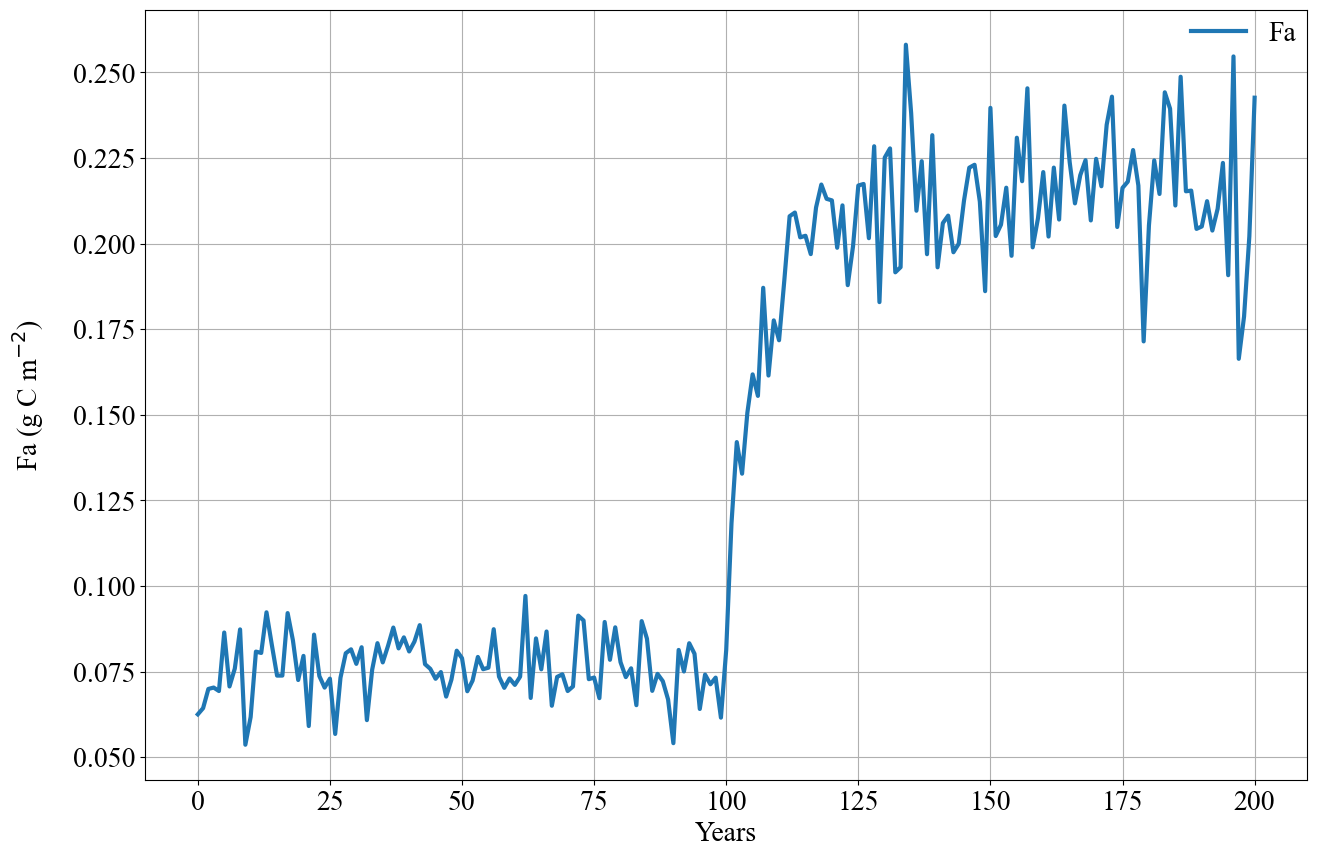

In [23]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fa"], lw=3, label="Fa")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fa (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

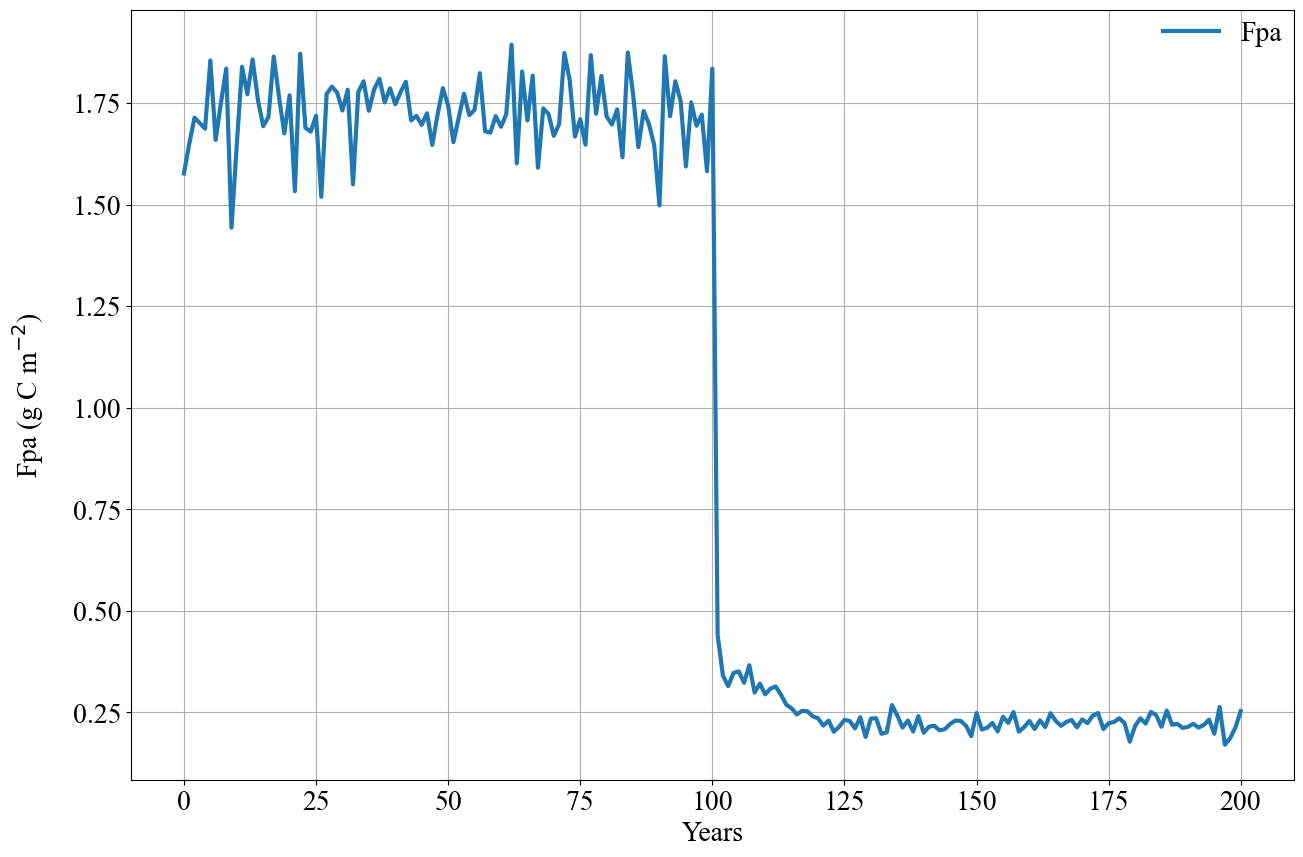

In [25]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fpa"], lw=3, label="Fpa")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fpa (g C m$^{-2}$)', rotation = 90, fontsize = fsl, labelpad = 20)

plt.show()

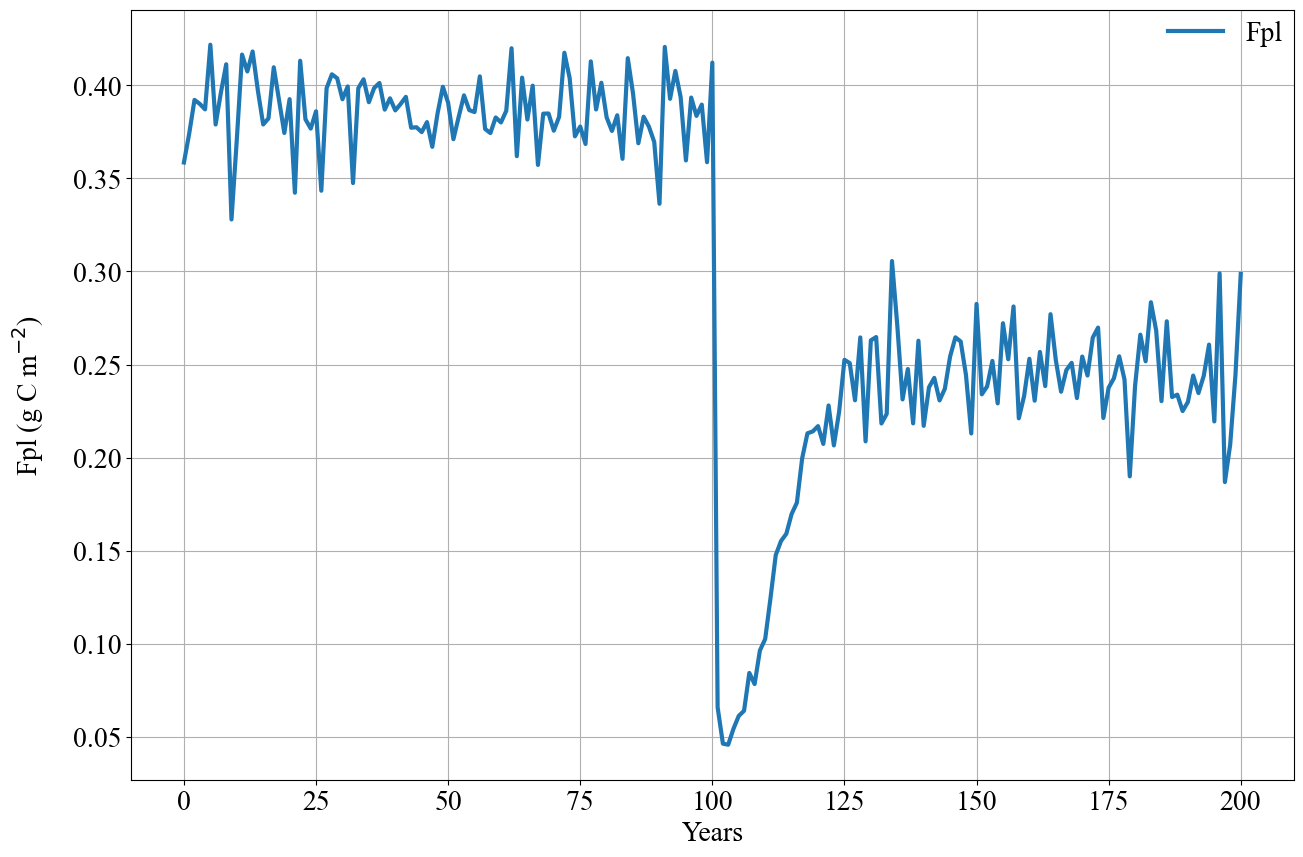

In [26]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fpl"], lw=3, label="Fpl")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fpl (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

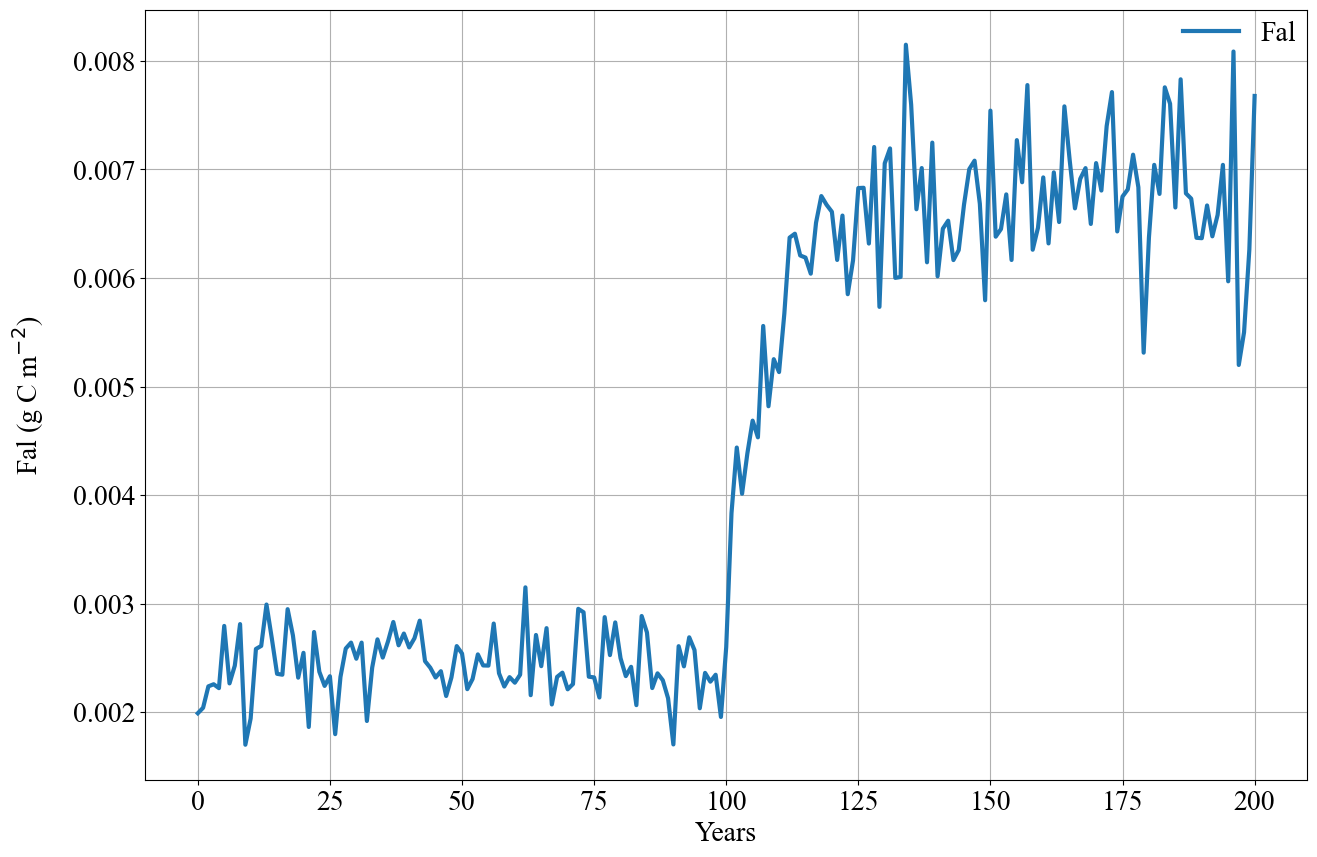

In [28]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fal"], lw=3, label="Fal")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fal (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

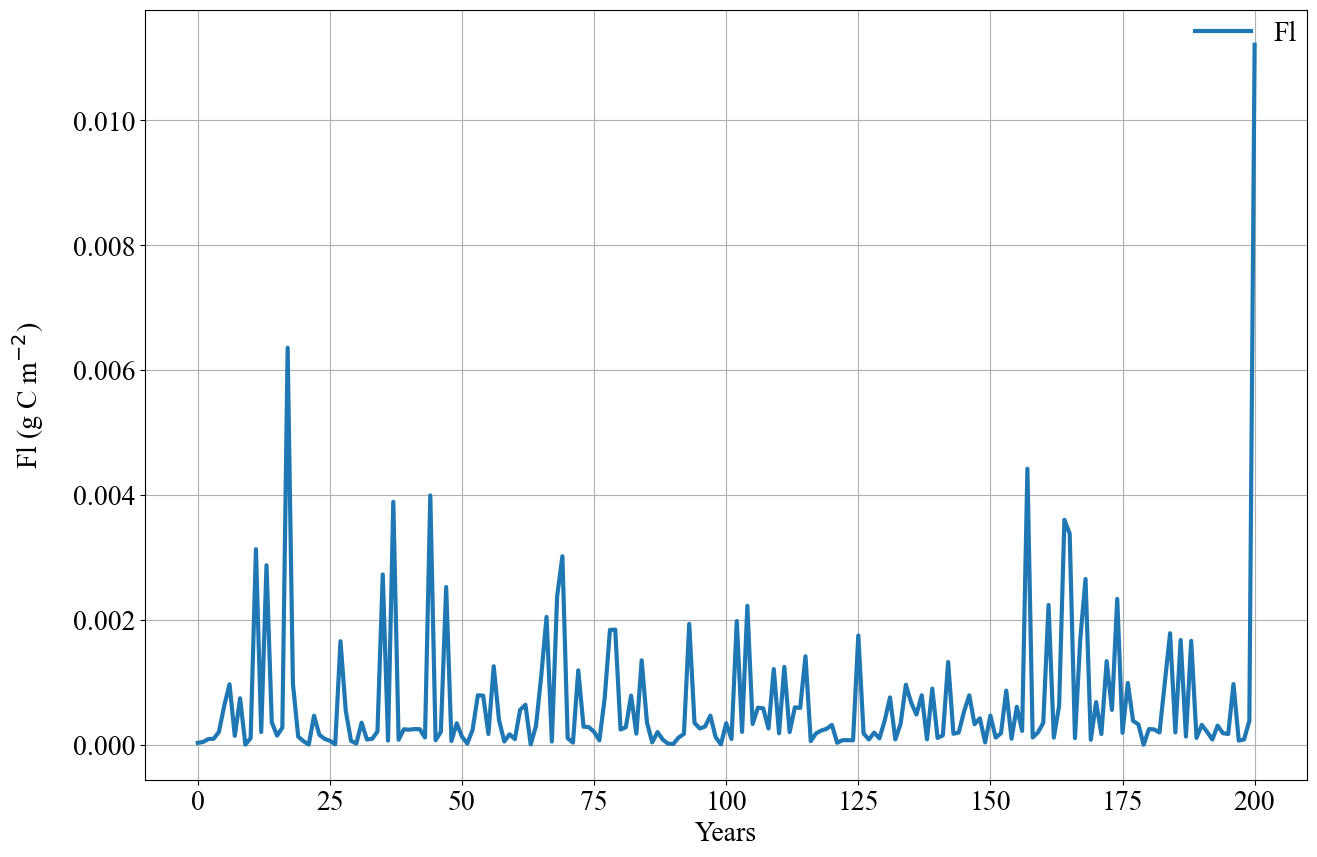

In [29]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fl"], lw=3, label="Fl")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fl (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

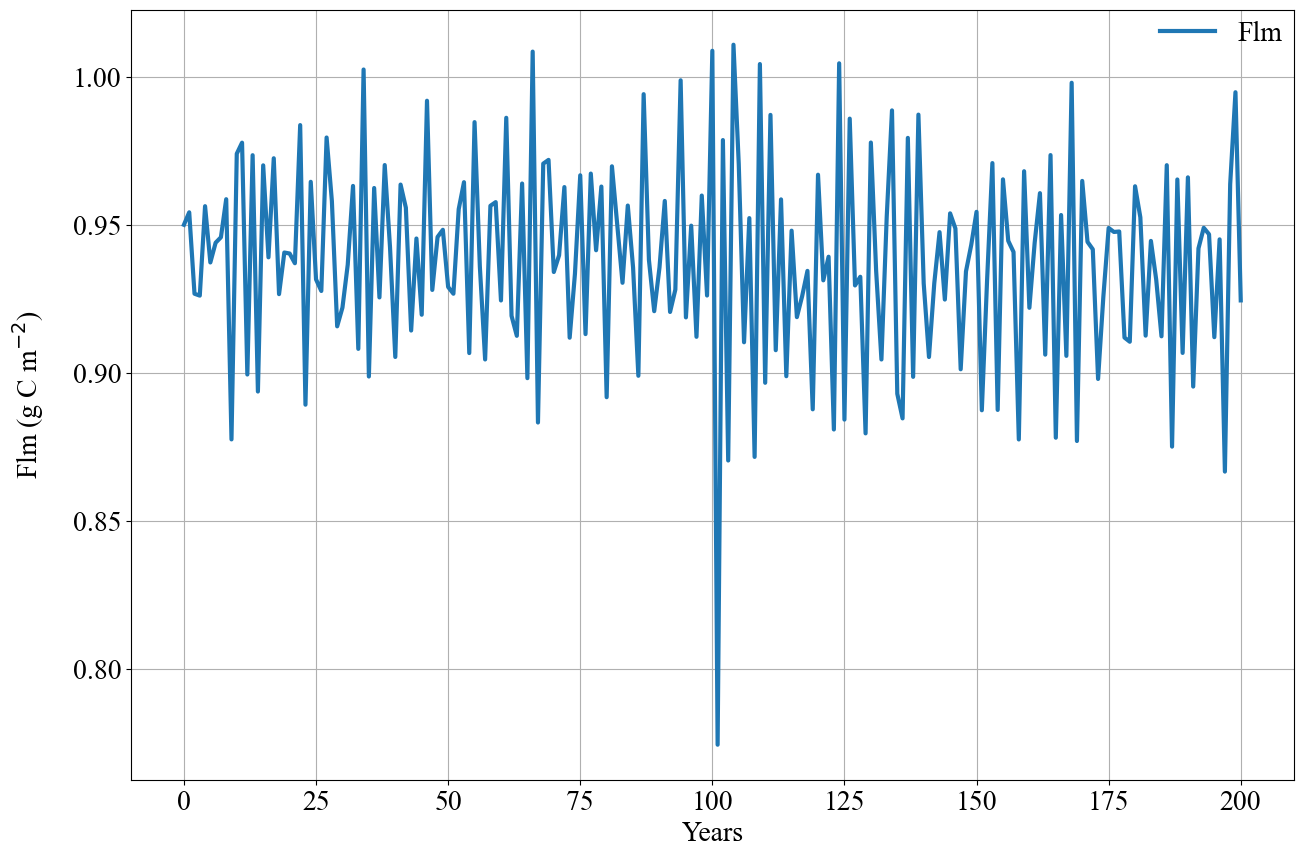

In [31]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Flm"], lw=3, label="Flm")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Flm (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

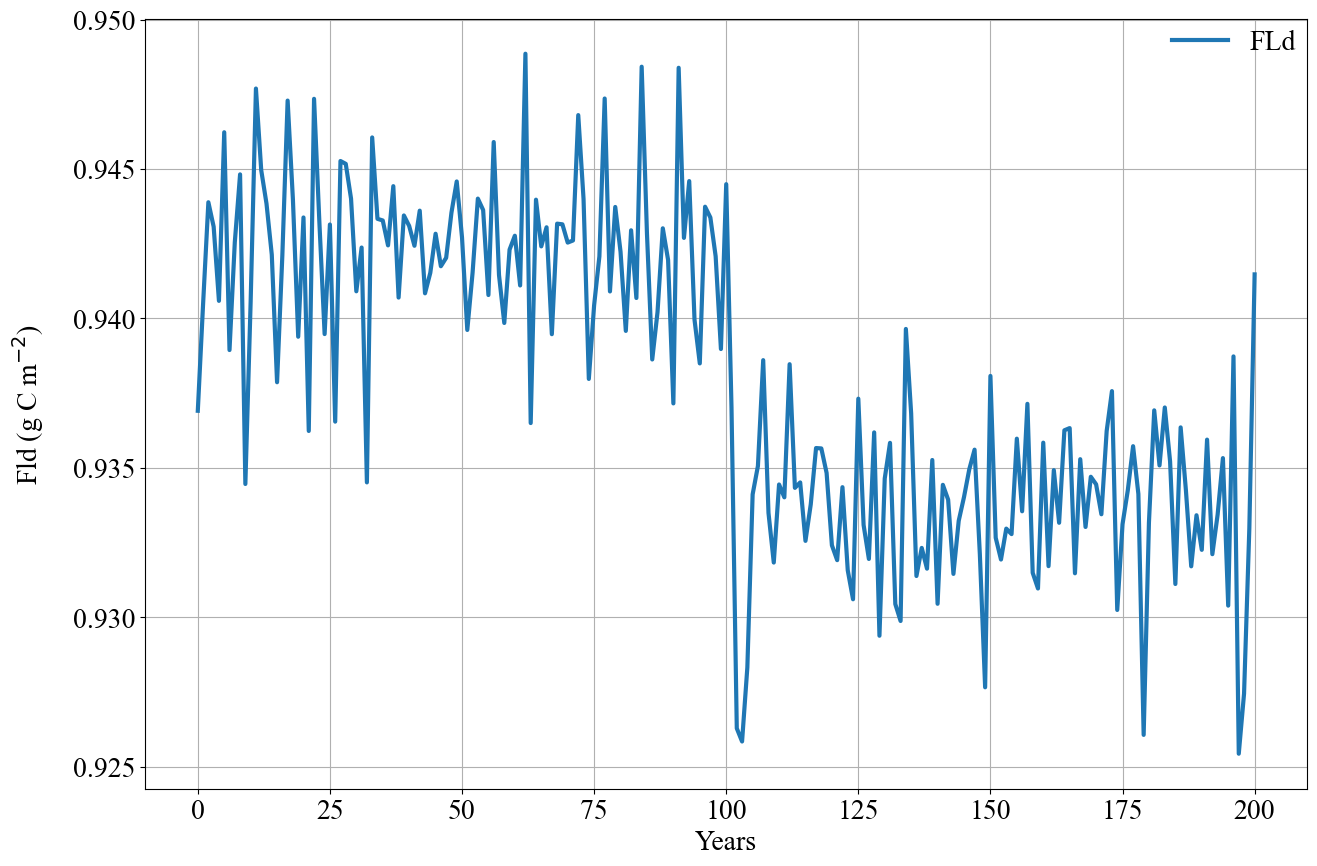

In [32]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fld"], lw=3, label="FLd")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fld (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

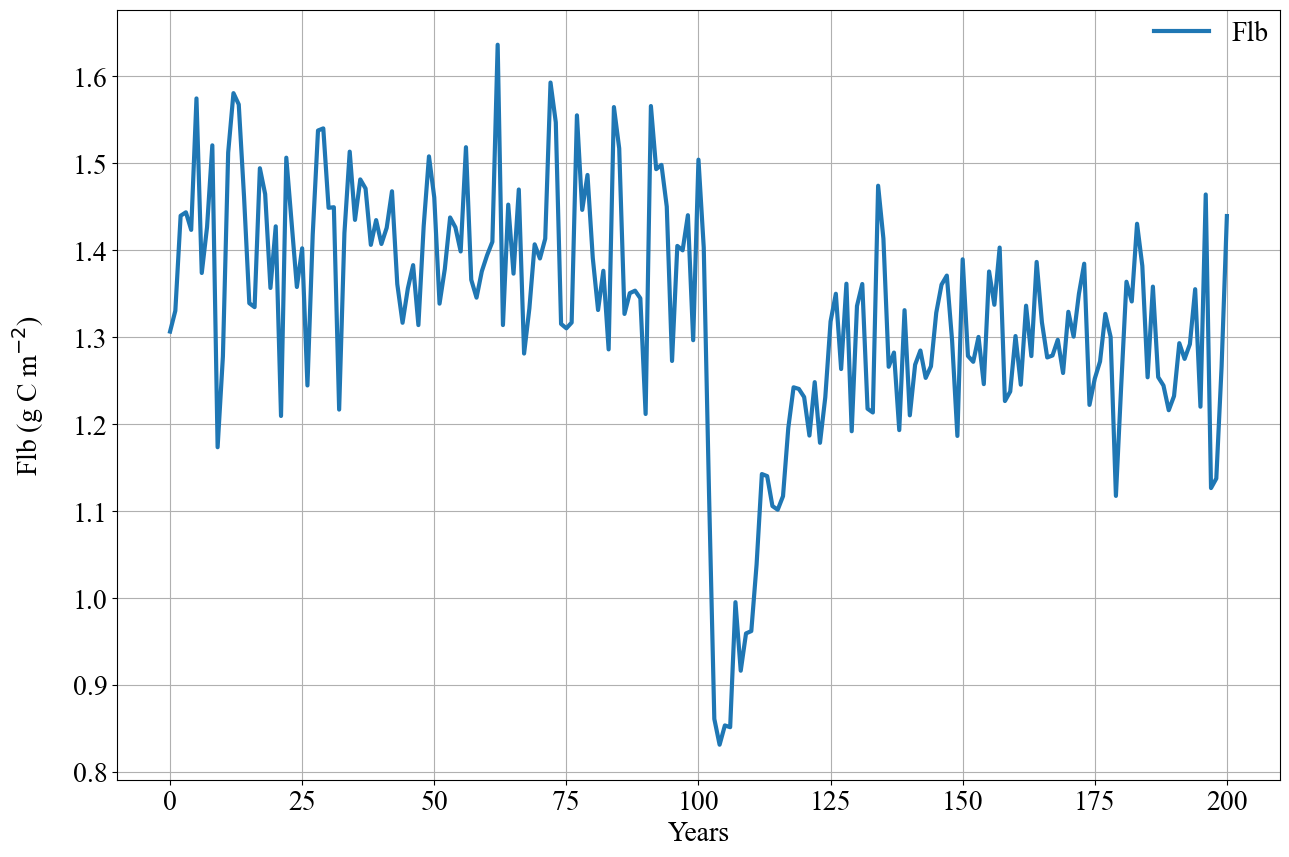

In [34]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Flb"], lw=3, label="Flb")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Flb (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

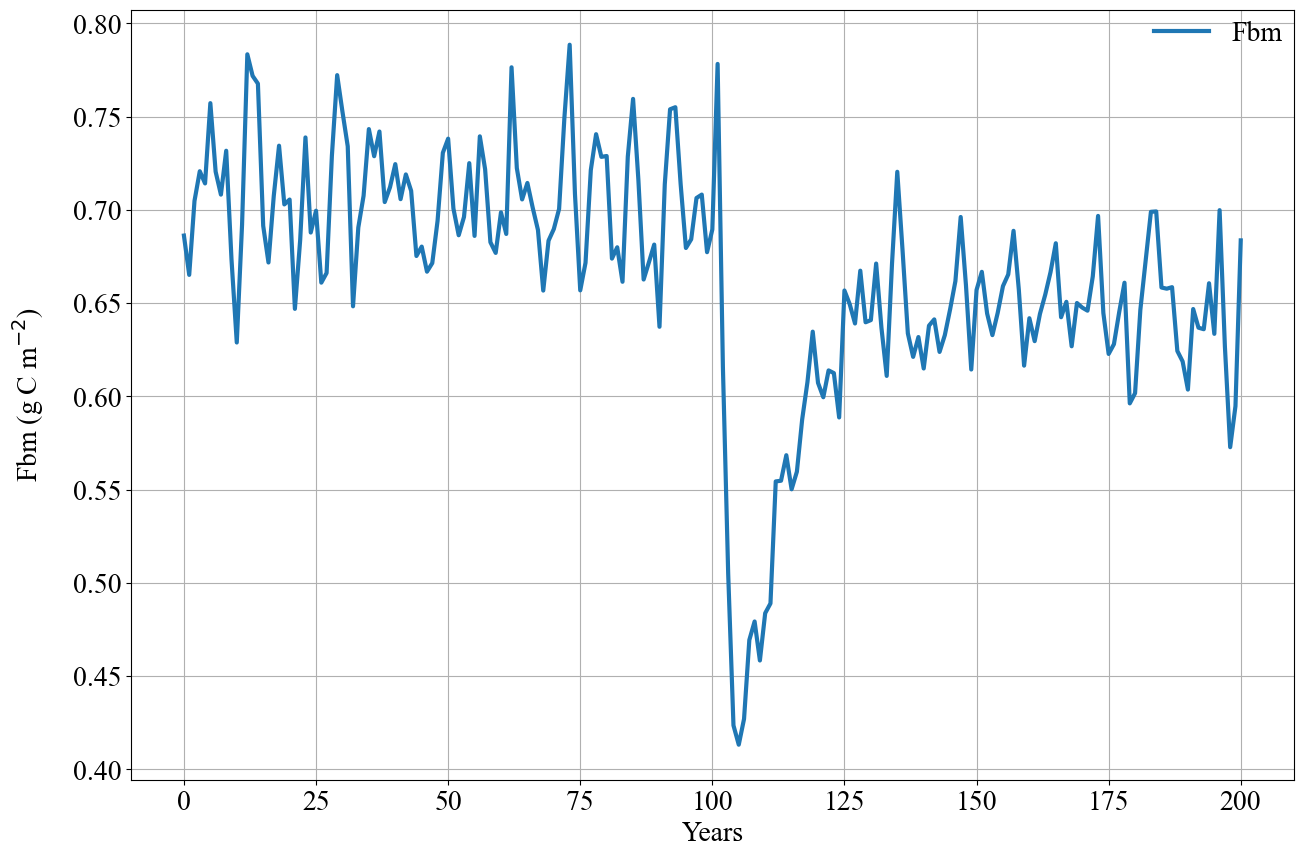

In [36]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["Fbm"], lw=3, label="Fbm")

ax1.grid(True)
ax1.legend(frameon=False, loc="upper right")
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'Fbm (g C m$^{-2}$)', rotation=90, fontsize=fsl, labelpad=20)

plt.show()

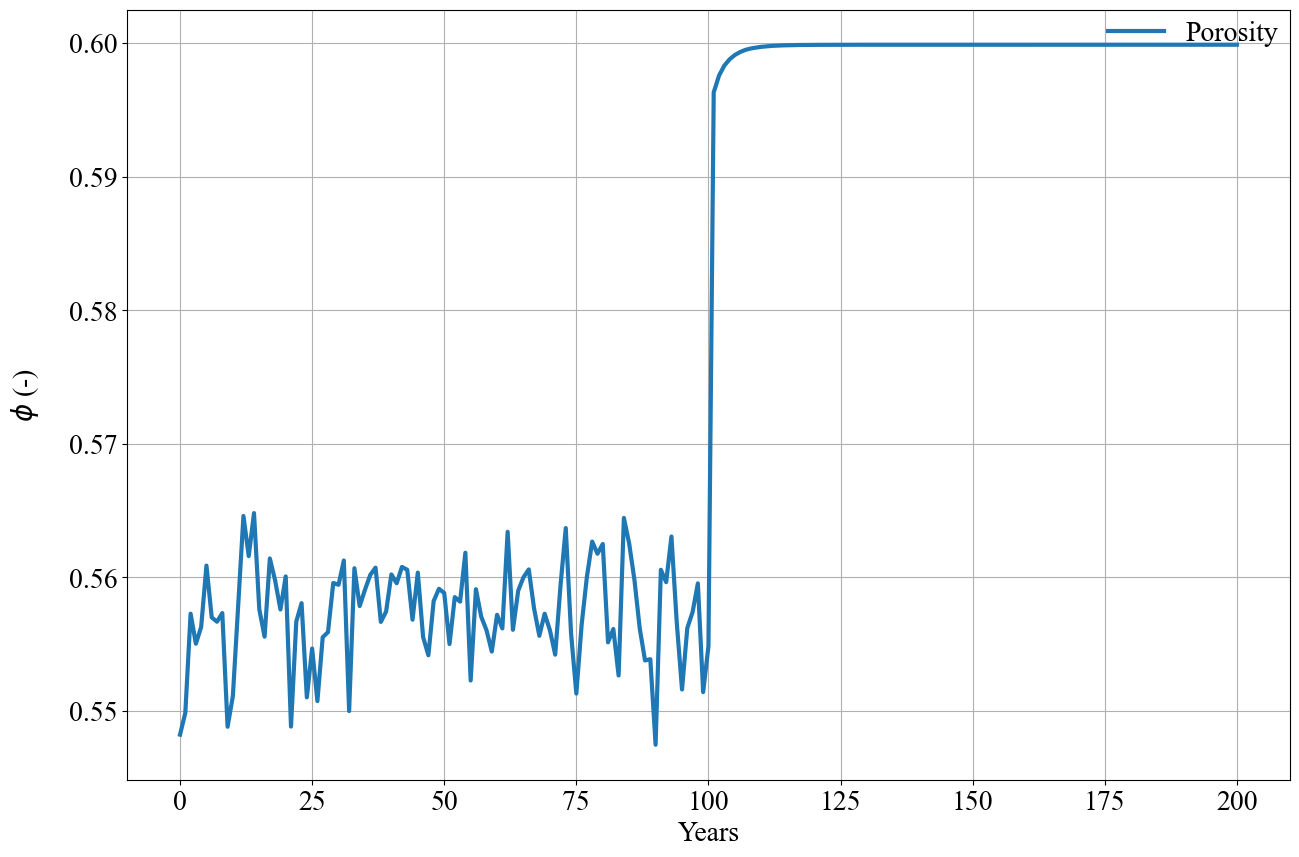

In [38]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

ax1.plot(df2["phi"], lw=3, label="Porosity")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'$\phi$ (-)', rotation=90, fontsize=fsl, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

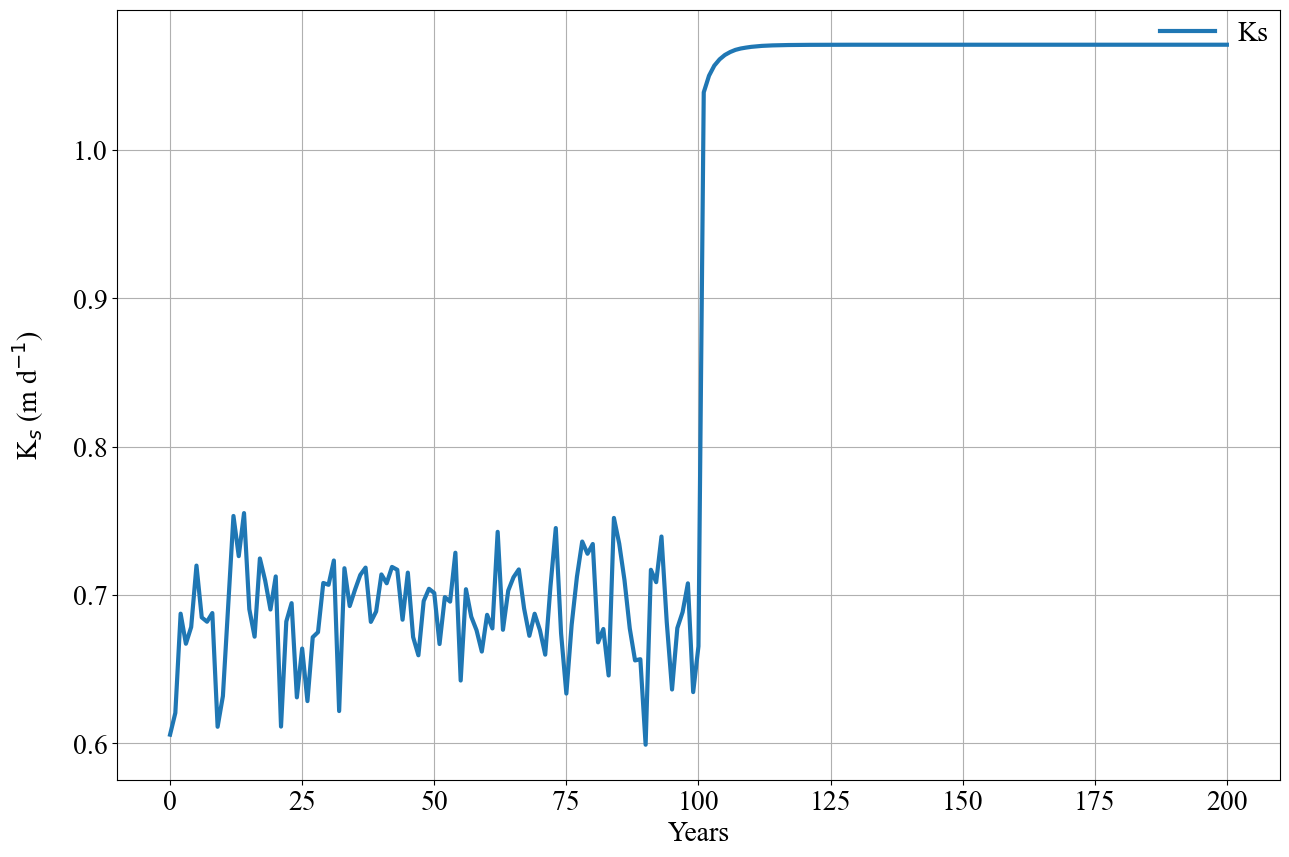

In [42]:
fig = plt.figure(figsize=(fw, fh))
ax1 = fig.add_subplot(111)

kstex = 0.172  #m/d

ax1.plot(df2['ksstr'] + kstex, lw=3, label="Ks")

ax1.grid(True)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.set_ylabel(r'K$_s$ (m d$^{-1}$)', rotation=90, fontsize=fsl, labelpad=20)
ax1.legend(frameon=False, loc="upper right")

plt.show()

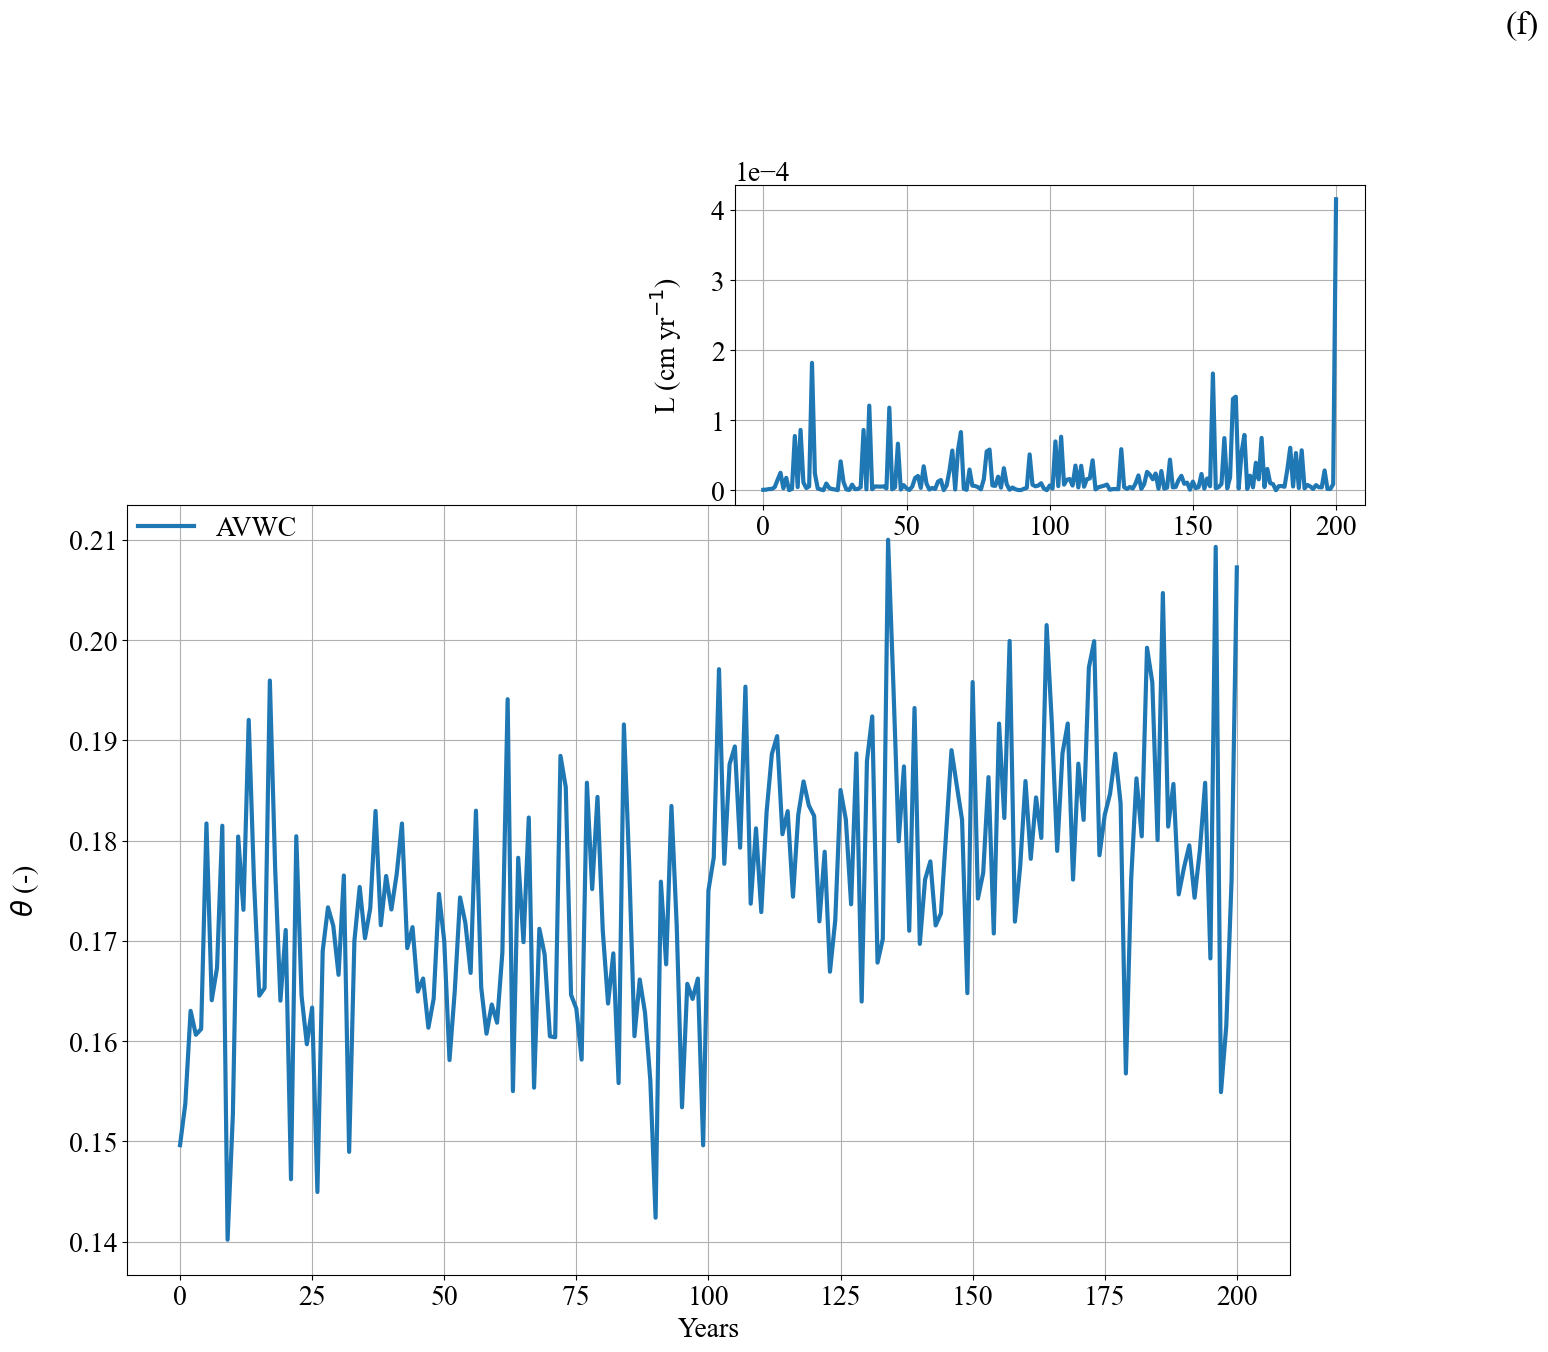

In [45]:
fig, ax1 = plt.subplots(figsize=(fw, fh))
left, bottom, width, height = [0.53, 0.88, 0.42, 0.32]
ax2 = fig.add_axes([left, bottom, width, height])

ax1.plot(df2['s'] * df2['phi'],lw=3,label="AVWC")
ax1.set_ylabel(r'$\theta$ (-)', rotation=90, fontsize = fsl, labelpad=20)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.grid(True)

ax2.plot(df2['lk']*(100),lw=3)
ax2.grid(True)
ax2.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
ax2.set_ylabel(r'L (cm yr$^{-1}$)', rotation=90, fontsize = fsl, labelpad=20)
ax1.set_xlabel(r'Years', fontsize=fsl)
ax1.legend(frameon=False, loc="upper left")
plt.title('(f)', x= 1.25, y= 1.45)

plt.show()